In [1]:
import pandas as pd

In [5]:
df = pd.read_csv('/US_Recession.csv')

In [6]:
print("Dataset Shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Dataset Shape: (344, 20)


,Unnamed: 0,Price_x,INDPRO,CPI,3 Mo,4 Mo,6 Mo,1 Yr,2 Yr,3 Yr,5 Yr,7 Yr,10 Yr,20 Yr,30 Yr,GDP,Rate,BBK_Index,Housing_Index,Recession
0,0,0.007111,0.046856,0.000000,1.000000,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,0.995788,0.981235,0.0,0.957474,0.00000,0.996359,0.463980,0.008161,0
1,1,0.009875,0.051140,0.001183,0.996264,0.0,0.991458,0.984958,0.987719,0.986550,0.998219,0.993983,0.976998,0.0,0.953608,0.00000,0.986650,0.449089,0.009267,0
2,2,0.012196,0.055858,0.005914,0.993773,0.0,0.976205,0.967509,0.962573,0.963743,0.969121,0.968712,0.950363,0.0,0.926546,0.00000,1.000000,0.422505,0.010159,0
3,3,0.012114,0.053475,0.009463,0.976339,0.0,0.960342,0.943442,0.938012,0.946199,0.956057,0.961492,0.951574,0.0,0.934278,0.00273,0.983010,0.397466,0.010395,0
4,4,0.005410,0.058643,0.015968,0.957659,0.0,0.939597,0.927798,0.930994,0.943860,0.971496,0.985560,0.987893,0.0,0.985825,0.00273,0.980583,0.373584,0.010048,1



Columns: ['Unnamed: 0', 'Price_x', 'INDPRO', 'CPI', '3 Mo', '4 Mo', '6 Mo', '1 Yr', '2 Yr', '3 Yr', '5 Yr', '7 Yr', '10 Yr', '20 Yr', '30 Yr', 'GDP', 'Rate', 'BBK_Index', 'Housing_Index', 'Recession']


In [7]:
# 1. Drop the unnecessary CSV index column if it exists
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# 2. Check if there are any missing/null values in the dataset
print("Missing values per column:\n", df.isnull().sum())

# 3. Drop rows with missing values (if any exist) to keep things clean
df = df.dropna()

# 4. Separate your Features (X) and Target (y)
X = df.drop(columns=['Recession'])
y = df['Recession']

print("\nFeatures shape (X):", X.shape)
print("Target shape (y):", y.shape)

Missing values per column:
 Price_x          0
INDPRO           0
CPI              0
3 Mo             0
4 Mo             0
6 Mo             0
1 Yr             0
2 Yr             0
3 Yr             0
5 Yr             0
7 Yr             0
10 Yr            0
20 Yr            0
30 Yr            0
GDP              0
Rate             0
BBK_Index        0
Housing_Index    0
Recession        0
dtype: int64

Features shape (X): (344, 18)
Target shape (y): (344,)


In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import pandas as pd

# 1. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

depths = range(1, 16)
results = []

for depth in depths:
    # 2. Train Decision Tree with a specific max_depth
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
    clf.fit(X_train, y_train)

    # 3. Evaluate Performance (Accuracy)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    # 4. Extract Structural Properties for our Custom Metric
    tree_depth = clf.get_depth()
    leaf_count = clf.get_n_leaves()
    # Count how many unique macroeconomic features the tree actually split on
    unique_features = len(set(clf.tree_.feature[clf.tree_.feature >= 0]))

    # 5. Calculate Custom Interpretability Score
    interp_score = 1.0 / (1.0 + 0.2 * tree_depth + 0.1 * leaf_count + 0.2 * unique_features)

    results.append({
        'Max_Depth_Set': depth,
        'Actual_Depth': tree_depth,
        'Leaves': leaf_count,
        'Unique_Features': unique_features,
        'Accuracy': acc,
        'Interpretability_Score': interp_score
    })

# Convert results into a clean DataFrame
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 Max_Depth_Set  Actual_Depth  Leaves  Unique_Features  Accuracy  Interpretability_Score
             1             1       2                1  0.913043                0.625000
             2             2       4                3  0.956522                0.416667
             3             3       6                5  0.942029                0.312500
             4             4       7                5  0.942029                0.285714
             5             5       8                5  0.942029                0.263158
             6             6      10                5  0.942029                0.238095
             7             7      12                6  0.942029                0.208333
             8             7      12                6  0.942029                0.208333
             9             7      12                6  0.942029                0.208333
            10             7      12                6  0.942029                0.208333
            11             7    

=== DECISION TREE RULES (Depth 2) ===
|--- BBK_Index <= 0.80
|   |--- Price_x <= 0.01
|   |   |--- class: 1
|   |--- Price_x >  0.01
|   |   |--- class: 0
|--- BBK_Index >  0.80
|   |--- CPI <= 0.28
|   |   |--- class: 0
|   |--- CPI >  0.28
|   |   |--- class: 1


=== DECISION TREE RULES (Depth 3) ===
|--- BBK_Index <= 0.80
|   |--- Price_x <= 0.01
|   |   |--- class: 1
|   |--- Price_x >  0.01
|   |   |--- Housing_Index <= 0.00
|   |   |   |--- class: 1
|   |   |--- Housing_Index >  0.00
|   |   |   |--- class: 0
|--- BBK_Index >  0.80
|   |--- GDP <= 0.23
|   |   |--- class: 0
|   |--- GDP >  0.23
|   |   |--- INDPRO <= 0.63
|   |   |   |--- class: 0
|   |   |--- INDPRO >  0.63
|   |   |   |--- class: 1



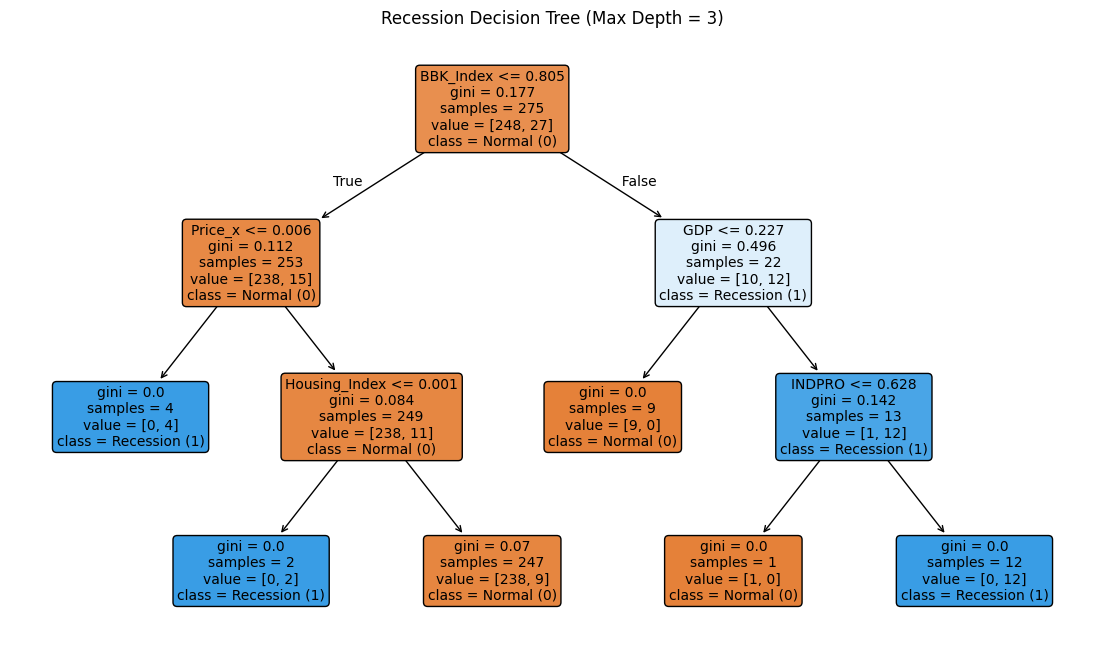

In [11]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
import matplotlib.pyplot as plt

# --- 1. Depth 2 Tree ---
clf_2 = DecisionTreeClassifier(max_depth=2, random_state=42)
clf_2.fit(X_train, y_train)

print("=== DECISION TREE RULES (Depth 2) ===")
tree_rules_2 = export_text(clf_2, feature_names=list(X.columns))
print(tree_rules_2)

# --- 2. Depth 3 Tree ---
clf_3 = DecisionTreeClassifier(max_depth=3, random_state=42)
clf_3.fit(X_train, y_train)

print("\n=== DECISION TREE RULES (Depth 3) ===")
tree_rules_3 = export_text(clf_3, feature_names=list(X.columns))
print(tree_rules_3)

# --- 3. Visual Matplotlib Diagram for Depth 3 ---
plt.figure(figsize=(14, 8))
plot_tree(clf_3, feature_names=X.columns, class_names=['Normal (0)', 'Recession (1)'], filled=True, rounded=True, fontsize=10)
plt.title("Recession Decision Tree (Max Depth = 3)")
plt.show()

In [9]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# 1. Train a Random Forest with controlled complexity
rf = RandomForestClassifier(n_estimators=50, max_depth=3, random_state=42)
rf.fit(X_train, y_train)

# 2. Evaluate Performance (Accuracy)
rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

# 3. Extract Metrics across all trees in the forest
# A Random Forest contains a list of individual trees in 'rf.estimators_'
rf_depths = [tree.get_depth() for tree in rf.estimators_]
rf_leaves = [tree.get_n_leaves() for tree in rf.estimators_]

avg_depth = np.mean(rf_depths)
avg_leaves = np.mean(rf_leaves)
# Count unique features used across all trees in the forest
unique_rf_features = len(set(
    feature_idx
    for tree in rf.estimators_
    for feature_idx in tree.tree_.feature if feature_idx >= 0
))

# 4. Calculate Custom Interpretability Score for the Random Forest
# (We penalize average depth, average leaves, and total unique features used)
rf_interp_score = 1.0 / (1.0 + 0.2 * avg_depth + 0.1 * avg_leaves + 0.2 * unique_rf_features)

print("=== MODEL COMPARISON ===")
print(f"Single Decision Tree (Depth 3) -> Accuracy: {acc:.4f} | Interpretability Score: {interp_score:.4f}")
print(f"Random Forest (n=50, depth=3)    -> Accuracy: {rf_acc:.4f} | Interpretability Score: {rf_interp_score:.4f}")
print(f"   - Average Tree Depth: {avg_depth:.2f}")
print(f"   - Average Leaves per Tree: {avg_leaves:.2f}")
print(f"   - Total Unique Features Used: {unique_rf_features}")

=== MODEL COMPARISON ===
Single Decision Tree (Depth 3) -> Accuracy: 0.9420 | Interpretability Score: 0.2083
Random Forest (n=50, depth=3)    -> Accuracy: 0.9420 | Interpretability Score: 0.1802
   - Average Tree Depth: 3.00
   - Average Leaves per Tree: 5.48
   - Total Unique Features Used: 17


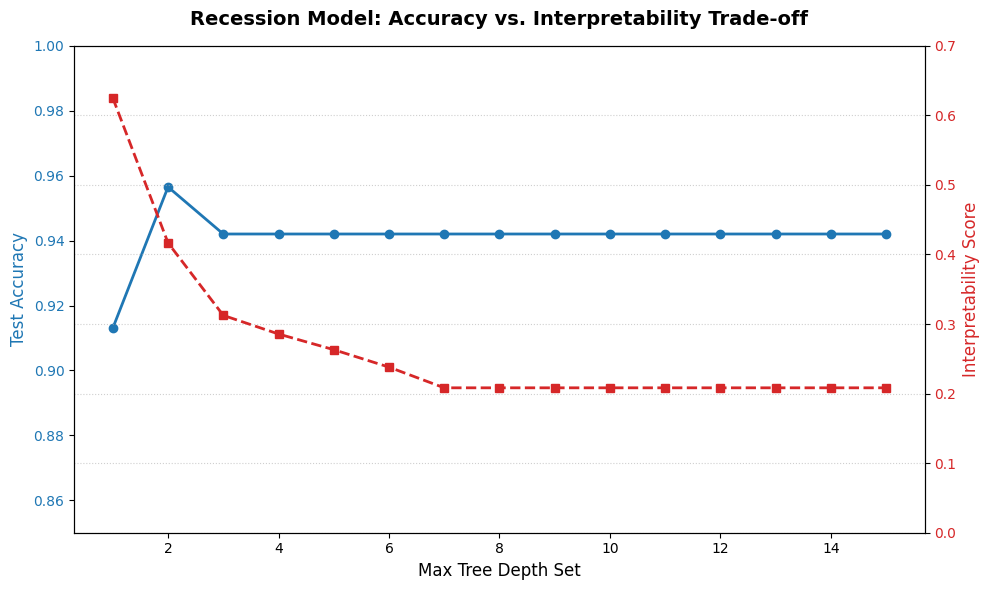

In [10]:
import matplotlib.pyplot as plt

# Create the figure and axis
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Accuracy on the primary y-axis
color = 'tab:blue'
ax1.set_xlabel('Max Tree Depth Set', fontsize=12)
ax1.set_ylabel('Test Accuracy', color=color, fontsize=12)
ax1.plot(results_df['Max_Depth_Set'], results_df['Accuracy'], color=color, marker='o', linewidth=2, label='Accuracy')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0.85, 1.0)

# Create a twin axis for the Interpretability Score
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Interpretability Score', color=color, fontsize=12)
ax2.plot(results_df['Max_Depth_Set'], results_df['Interpretability_Score'], color=color, marker='s', linestyle='--', linewidth=2, label='Interpretability Score')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 0.7)

plt.title('Recession Model: Accuracy vs. Interpretability Trade-off', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()